# PortfolioLens: a repeatable portfolio review

**Working prototype for financial analyst and fintech product manager interviews.**

The underlying idea comes from an APAN 5540 team project. This notebook demonstrates the new workflow using **synthetic prices**, not actual security performance. It compares the supplied 18.4% AVGO / 12.6% ETN / 69.0% PGR allocation, equal weights, and capped minimum variance against SPY.

Run from the repository's installed environment. See `docs/PROVENANCE.md` for contribution boundaries.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "portfoliolens").exists():
    root = root.parent
sys.path.insert(0, str(root))
import pandas as pd
from portfoliolens.data import demo_prices, fingerprint
from portfoliolens.engine import Config, review
from portfoliolens.report import write_report
prices = demo_prices()
holdings = {"AVGO": .184, "ETN": .126, "PGR": .69}
config = Config(lookback=252, max_weight=.50, cost_bps=10, annual_rf=.04)
print("SYNTHETIC DEMO — these are not historical market prices")
prices.head()

SYNTHETIC DEMO — these are not historical market prices


,AVGO,ETN,PGR,SPY
2022-01-03,100.000000,100.000000,100.000000,100.000000
2022-01-04,104.659133,98.457622,100.391149,100.870760
2022-01-05,108.862973,99.679185,100.786433,101.063829
2022-01-06,109.420606,97.899345,100.667094,101.284787
2022-01-07,111.612965,101.856092,101.515012,103.138529


## 1. State the decision

The supplied allocation puts 69% in one stock at rebalance. What changes if the analyst compares it with an equal-weight baseline and a covariance-based alternative capped at 50%? The goal is to explain the tradeoff, not to select whichever scenario has the best hindsight return.

In [2]:
result = review(prices, holdings, config)
result["metrics"].round(4)

,Total return,Annualized geometric return,Annualized volatility,Maximum drawdown,Sharpe ratio,Information ratio,Beta,Gross traded notional / NAV (sum),Cost fractions (sum)
SPY,1.5490,0.3660,0.1528,-0.1284,1.8618,NaN,1.0000,1.0000,0.0010
Current allocation,1.2758,0.3154,0.1439,-0.1576,1.7052,-0.3238,0.6302,2.1826,0.0022
Equal weight,1.9840,0.4397,0.1872,-0.1555,1.8318,0.4518,0.8924,2.5510,0.0026
Capped min variance,1.3391,0.3274,0.1545,-0.1366,1.6575,-0.2566,0.7484,2.4183,0.0024


## 2. Inspect the allocation and execution assumptions

Targets are chosen from prior observations and applied at the preceding close. They are reset monthly; weights drift between trades. Costs apply to gross buys plus sells, including initial entry. The optimized cap applies at rebalance, not continuously.

In [3]:
result["trades"]["Capped min variance"].head()

,return_date,gross_turnover,cost_fraction,AVGO,ETN,PGR
0,2022-12-22,1.000000,0.001000,0.112415,0.387585,0.5
1,2023-01-02,0.008469,0.000008,0.106340,0.393660,0.5
2,2023-02-01,0.014280,0.000014,0.107235,0.392765,0.5
3,2023-03-01,0.031473,0.000031,0.104859,0.395141,0.5
4,2023-04-03,0.057273,0.000057,0.124012,0.375988,0.5


## 3. Check cost sensitivity

Use the same synthetic history and methods for each assumption. Compare terminal returns rather than treating summed per-trade cost fractions as exact performance drag.

In [4]:
sensitivity = {}
for bps in [0, 10, 25]:
    run = review(prices, holdings, Config(cost_bps=bps))
    sensitivity[f"{bps} bps"] = run["metrics"]["Total return"]
pd.DataFrame(sensitivity).round(4)

,0 bps,10 bps,25 bps
SPY,1.5516,1.5490,1.5452
Current allocation,1.2808,1.2758,1.2683
Equal weight,1.9916,1.9840,1.9726
Capped min variance,1.3447,1.3391,1.3306


## 4. Generate the decision brief

The HTML report embeds its chart and can be opened offline. The output directory also contains metrics, trade logs, net returns, configuration, and a data fingerprint.

Saved reports/notebook-demo/review.html


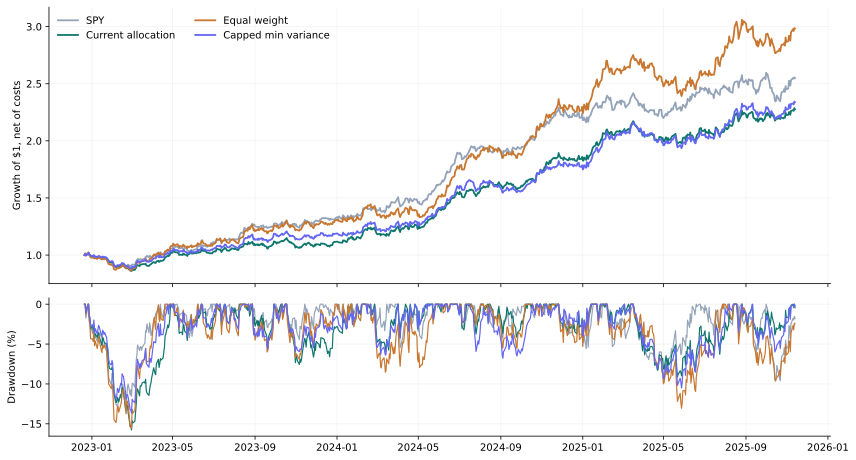

In [5]:
report = write_report(result, root / "reports" / "notebook-demo",
                      "SYNTHETIC DEMO - simulated prices, not historical market results",
                      fingerprint(prices))
print("Saved reports/notebook-demo/review.html")
from IPython.display import SVG, display
display(SVG(filename=str(report.parent / "performance.svg")))

## 5. Interview discussion

- Which alternative reduces concentration, and what return or cost tradeoff accompanies it?
- Why does the optimizer use previous observations only?
- Why is this not an independent test of the original stock selection?
- What would a user need before using this in a recurring review?

**Still pending:** independent real-data reconciliation, observed user feedback, and measured workflow impact. For a market run, follow the opt-in download and review commands in the README. Do not describe these synthetic results as investment performance.